In [1]:
# import Libraries

import pandas as pd
import numpy as np
import matplotlib as plt
import seaborn as sns
import plotly as px

In [3]:
#Load dataset & show first 4 rows

df=pd.read_csv('powerconsumption.csv')
df.head()

,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
0,1/1/2017 0:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
1,1/1/2017 0:10,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2,1/1/2017 0:20,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373
3,1/1/2017 0:30,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
4,1/1/2017 0:40,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964


In [4]:
# check data structures

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 52416 entries, 0 to 52415
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Datetime                52416 non-null  str    
 1   Temperature             52416 non-null  float64
 2   Humidity                52416 non-null  float64
 3   WindSpeed               52416 non-null  float64
 4   GeneralDiffuseFlows     52416 non-null  float64
 5   DiffuseFlows            52416 non-null  float64
 6   PowerConsumption_Zone1  52416 non-null  float64
 7   PowerConsumption_Zone2  52416 non-null  float64
 8   PowerConsumption_Zone3  52416 non-null  float64
dtypes: float64(8), str(1)
memory usage: 3.6 MB


In [5]:
# check dimensions

df.shape

(52416, 9)

In [6]:
# check columns name

df.columns

Index(['Datetime', 'Temperature', 'Humidity', 'WindSpeed',
       'GeneralDiffuseFlows', 'DiffuseFlows', 'PowerConsumption_Zone1',
       'PowerConsumption_Zone2', 'PowerConsumption_Zone3'],
      dtype='str')

In [7]:
# check for missing values

df.isnull().sum()

Datetime                  0
Temperature               0
Humidity                  0
WindSpeed                 0
GeneralDiffuseFlows       0
DiffuseFlows              0
PowerConsumption_Zone1    0
PowerConsumption_Zone2    0
PowerConsumption_Zone3    0
dtype: int64

In [8]:
# check for duplicate value

df.duplicated().sum()

np.int64(0)

In [9]:
# check inconsistent numerical values

df.describe()

,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
count,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000
mean,18.810024,68.259518,1.959489,182.696614,75.028022,32344.970564,21042.509082,17835.406218
std,5.815476,15.551177,2.348862,264.400960,124.210949,7130.562564,5201.465892,6622.165099
min,3.247000,11.340000,0.050000,0.004000,0.011000,13895.696200,8560.081466,5935.174070
25%,14.410000,58.310000,0.078000,0.062000,0.122000,26310.668692,16980.766032,13129.326630
50%,18.780000,69.860000,0.086000,5.035500,4.456000,32265.920340,20823.168405,16415.117470
75%,22.890000,81.400000,4.915000,319.600000,101.000000,37309.018185,24713.717520,21624.100420
max,40.010000,94.800000,6.483000,1163.000000,936.000000,52204.395120,37408.860760,47598.326360


In [10]:
df['Datetime'] = pd.to_datetime(df['Datetime'],errors='coerce')

In [11]:
df['Datetime'].dtype

dtype('<M8[us]')

In [12]:
# check for invalid datetime values
df['Datetime'].isna().sum()

# check duplicate timestamps
df['Datetime'].duplicated().sum()

# Check duplicate rows
df.duplicated().sum()


np.int64(0)

In [13]:
# Data validation checks

checks = {
'Humidity below 0': (df['Humidity'] < 0).sum(),
'Humidity above 100': (df['Humidity'] > 100).sum(),
'Negative wind speed': (df['WindSpeed'] < 0).sum(),
'Negative general diffuse flows': (df['GeneralDiffuseFlows'] < 0).sum(),
'Negative diffuse flows': (df['DiffuseFlows'] < 0).sum(),
'Negative Zone 1 consumption': (df['PowerConsumption_Zone1'] < 0).sum(),
'Negative Zone 2 consumption': (df['PowerConsumption_Zone2'] < 0).sum(),
'Negative Zone 3 consumption': (df['PowerConsumption_Zone3'] < 0).sum()
}
pd.Series(checks)

Humidity below 0                  0
Humidity above 100                0
Negative wind speed               0
Negative general diffuse flows    0
Negative diffuse flows            0
Negative Zone 1 consumption       0
Negative Zone 2 consumption       0
Negative Zone 3 consumption       0
dtype: int64

In [14]:
# descriptive statistics
consumption_cols = [
    'PowerConsumption_Zone1',
    'PowerConsumption_Zone2',
    'PowerConsumption_Zone3'
]

df[consumption_cols].describe()

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
count,52416.000000,52416.000000,52416.000000
mean,32344.970564,21042.509082,17835.406218
std,7130.562564,5201.465892,6622.165099
min,13895.696200,8560.081466,5935.174070
25%,26310.668692,16980.766032,13129.326630
50%,32265.920340,20823.168405,16415.117470
75%,37309.018185,24713.717520,21624.100420
max,52204.395120,37408.860760,47598.326360


In [16]:
# outliers using IQR method

for col in consumption_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print(f"\n{col}")
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Number of Outliers:", len(outliers))


PowerConsumption_Zone1
Lower Bound: 9813.144453749996
Upper Bound: 53806.542423750005
Number of Outliers: 0

PowerConsumption_Zone2
Lower Bound: 5381.338801250002
Upper Bound: 36313.144751249994
Number of Outliers: 7

PowerConsumption_Zone3
Lower Bound: 387.16594500000065
Upper Bound: 34366.261105
Number of Outliers: 1191


In [17]:
# percentage of outliers

for col in consumption_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outlier_count = (
        (df[col] < lower) |
        (df[col] > upper)
    ).sum()

    percentage = (outlier_count / len(df)) * 100

    print(f"{col}: {outlier_count} outliers ({percentage:.2f}%)")

PowerConsumption_Zone1: 0 outliers (0.00%)
PowerConsumption_Zone2: 7 outliers (0.01%)
PowerConsumption_Zone3: 1191 outliers (2.27%)


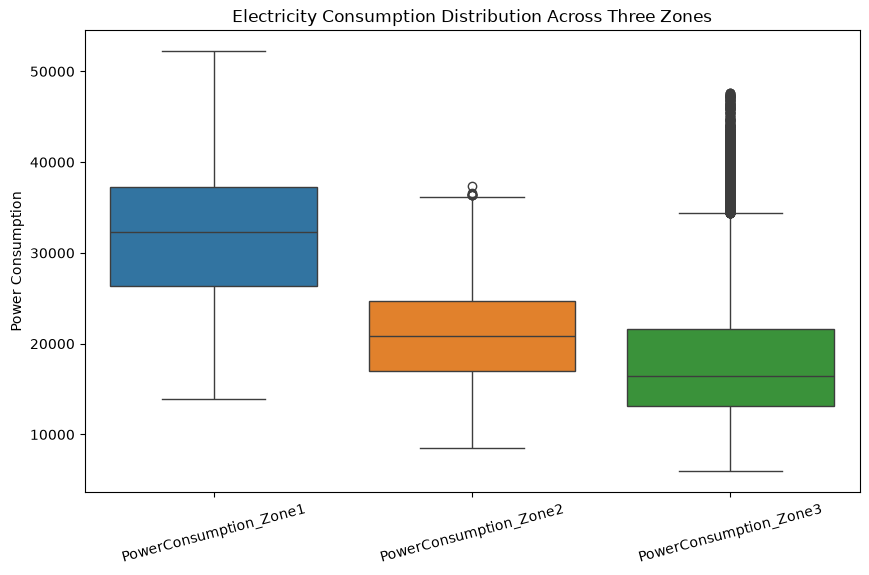

In [18]:
# Visualise the outliers

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.boxplot(data=df[[
    'PowerConsumption_Zone1',
    'PowerConsumption_Zone2',
    'PowerConsumption_Zone3'
]])

plt.title('Electricity Consumption Distribution Across Three Zones')
plt.ylabel('Power Consumption')
plt.xticks(rotation=15)
plt.show()

In [19]:
# Time based column

# Extract year
df['Year'] = df['Datetime'].dt.year

# Extract month
df['Month'] = df['Datetime'].dt.month

# Extract day
df['Day'] = df['Datetime'].dt.day

# Extract hour
df['Hour'] = df['Datetime'].dt.hour

# Extract day of the week
df['Day_of_Week'] = df['Datetime'].dt.day_name()

# Extract date
df['Date'] = df['Datetime'].dt.date

In [20]:
# Datetime data type

df['Datetime'].dtype

dtype('<M8[us]')

In [21]:

df['Datetime'] = pd.to_datetime(df['Datetime'], errors='coerce')

In [22]:
df['Datetime'].dtype

dtype('<M8[us]')

In [19]:
# Time based column

# Extract year
df['Year'] = df['Datetime'].dt.year

# Extract month
df['Month'] = df['Datetime'].dt.month

# Extract day
df['Day'] = df['Datetime'].dt.day

# Extract hour
df['Hour'] = df['Datetime'].dt.hour

# Extract day of the week
df['Day_of_Week'] = df['Datetime'].dt.day_name()

# Extract date
df['Date'] = df['Datetime'].dt.date

In [23]:
df[['Datetime', 'Year', 'Month', 'Day',
    'Hour', 'Day_of_Week', 'Date']].head(10)

,Datetime,Year,Month,Day,Hour,Day_of_Week,Date
0,2017-01-01 00:00:00,2017,1,1,0,Sunday,2017-01-01
1,2017-01-01 00:10:00,2017,1,1,0,Sunday,2017-01-01
2,2017-01-01 00:20:00,2017,1,1,0,Sunday,2017-01-01
3,2017-01-01 00:30:00,2017,1,1,0,Sunday,2017-01-01
4,2017-01-01 00:40:00,2017,1,1,0,Sunday,2017-01-01
5,2017-01-01 00:50:00,2017,1,1,0,Sunday,2017-01-01
6,2017-01-01 01:00:00,2017,1,1,1,Sunday,2017-01-01
7,2017-01-01 01:10:00,2017,1,1,1,Sunday,2017-01-01
8,2017-01-01 01:20:00,2017,1,1,1,Sunday,2017-01-01
9,2017-01-01 01:30:00,2017,1,1,1,Sunday,2017-01-01


In [24]:
df.columns.tolist()

['Datetime',
 'Temperature',
 'Humidity',
 'WindSpeed',
 'GeneralDiffuseFlows',
 'DiffuseFlows',
 'PowerConsumption_Zone1',
 'PowerConsumption_Zone2',
 'PowerConsumption_Zone3',
 'Year',
 'Month',
 'Day',
 'Hour',
 'Day_of_Week',
 'Date']

In [25]:
# Select electricity consumption columns
consumption_cols = [
    'PowerConsumption_Zone1',
    'PowerConsumption_Zone2',
    'PowerConsumption_Zone3'
]

# Overall consumption statistics
consumption_summary = df[consumption_cols].agg(
    ['sum', 'mean', 'min', 'max', 'std']
)

consumption_summary

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
sum,1.695394e+09,1.102964e+09,9.348607e+08
mean,3.234497e+04,2.104251e+04,1.783541e+04
min,1.389570e+04,8.560081e+03,5.935174e+03
max,5.220440e+04,3.740886e+04,4.759833e+04
std,7.130563e+03,5.201466e+03,6.622165e+03


In [26]:
df['Total_Consumption'] = df[consumption_cols].sum(axis=1)

In [27]:
# overall consumption across three zones

df[consumption_cols].describe()

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
count,52416.000000,52416.000000,52416.000000
mean,32344.970564,21042.509082,17835.406218
std,7130.562564,5201.465892,6622.165099
min,13895.696200,8560.081466,5935.174070
25%,26310.668692,16980.766032,13129.326630
50%,32265.920340,20823.168405,16415.117470
75%,37309.018185,24713.717520,21624.100420
max,52204.395120,37408.860760,47598.326360


In [28]:
df['Total_Consumption'].describe()

count     52416.000000
mean      71222.885864
std       17143.138964
min       36785.039739
25%       56499.074640
50%       69788.790940
75%       83749.172310
max      134208.145950
Name: Total_Consumption, dtype: float64

In [29]:
# Average consumption by zones

average_consumption = df[consumption_cols].mean()

print(average_consumption)

PowerConsumption_Zone1    32344.970564
PowerConsumption_Zone2    21042.509082
PowerConsumption_Zone3    17835.406218
dtype: float64


In [30]:
# each zone contribution

zone_contribution = (
    df[consumption_cols].sum() /
    df[consumption_cols].sum().sum()
) * 100

print(zone_contribution.round(2))

PowerConsumption_Zone1    45.41
PowerConsumption_Zone2    29.54
PowerConsumption_Zone3    25.04
dtype: float64


In [31]:
# Highest and lowest consumption periods
# maximum and minimum consumption records for each zone

for col in consumption_cols:

    max_idx = df[col].idxmax()
    min_idx = df[col].idxmin()

    print(f'\n{col}')

    print('Highest Consumption:')
    print(df.loc[max_idx, ['Datetime', col]])

    print('Lowest Consumption:')
    print(df.loc[min_idx, ['Datetime', col]])


PowerConsumption_Zone1
Highest Consumption:
Datetime                  2017-08-07 20:20:00
PowerConsumption_Zone1            52204.39512
Name: 31514, dtype: object
Lowest Consumption:
Datetime                  2017-01-15 07:30:00
PowerConsumption_Zone1             13895.6962
Name: 2061, dtype: object

PowerConsumption_Zone2
Highest Consumption:
Datetime                  2017-07-24 19:40:00
PowerConsumption_Zone2            37408.86076
Name: 29494, dtype: object
Lowest Consumption:
Datetime                  2017-04-02 06:10:00
PowerConsumption_Zone2            8560.081466
Name: 13141, dtype: object

PowerConsumption_Zone3
Highest Consumption:
Datetime                  2017-07-24 20:10:00
PowerConsumption_Zone3            47598.32636
Name: 29497, dtype: object
Lowest Consumption:
Datetime                  2017-12-11 07:00:00
PowerConsumption_Zone3             5935.17407
Name: 49578, dtype: object


In [32]:
# combined consumption

highest = df.loc[df['Total_Consumption'].idxmax()]
lowest = df.loc[df['Total_Consumption'].idxmin()]

print("Highest consumption period:")
print(highest[['Datetime', 'Total_Consumption']])

print("\nLowest consumption period:")
print(lowest[['Datetime', 'Total_Consumption']])

Highest consumption period:
Datetime             2017-07-24 20:10:00
Total_Consumption           134208.14595
Name: 29497, dtype: object

Lowest consumption period:
Datetime             2017-12-03 07:20:00
Total_Consumption           36785.039739
Name: 48428, dtype: object


In [33]:
# Hourly consumption patterns

hourly_consumption = df.groupby('Hour')[consumption_cols].mean()

hourly_consumption

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Hour,,,
0,30217.235372,19692.073550,18657.222811
1,27565.533030,17765.078949,16970.804696
2,26292.688917,16730.156092,15981.096176
3,25338.122851,16052.585288,15238.605002
4,24633.576717,15624.081077,14671.039080
5,23437.577276,14974.907723,13226.380008
6,23203.597394,14934.698604,12051.599729
7,24038.353352,15719.115067,11667.864458
8,26583.262396,17529.678454,12793.786057


In [34]:
# peak and lowest average consumption hours

for col in consumption_cols:

    print(f'\n{col}')

    print('Peak hour:', hourly_consumption[col].idxmax())

    print('Lowest hour:', hourly_consumption[col].idxmin())


PowerConsumption_Zone1
Peak hour: 20
Lowest hour: 6

PowerConsumption_Zone2
Peak hour: 20
Lowest hour: 6

PowerConsumption_Zone3
Peak hour: 20
Lowest hour: 7


In [35]:
# Daily and weekly consumption patterns
# Daily consumption
daily_consumption = df.groupby('Date')[consumption_cols].mean()

In [36]:
# Daily and weekly consumption patterns
# Weekly consumption

week_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

weekly_consumption = (
    df.groupby('Day_of_Week')[consumption_cols]
    .mean()
    .reindex(week_order)
)

weekly_consumption

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Day_of_Week,,,
Monday,32615.410633,21280.065085,17809.081562
Tuesday,32713.030148,21518.599887,17831.688173
Wednesday,32871.759018,21627.362715,17851.395059
Thursday,32842.484416,21845.164469,17843.692103
Friday,32338.995905,21461.038263,17545.971382
Saturday,32253.034345,20585.955724,18011.187469
Sunday,30780.079481,18979.377434,17954.827782


In [37]:
# Monthly consumption patterns

monthly_consumption = df.groupby('Month')[consumption_cols].mean()

monthly_consumption

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Month,,,
1,31032.493535,19394.444717,17746.095349
2,30985.753632,18787.793096,17335.002154
3,31155.165408,18457.937484,16947.686004
4,31169.768210,17633.966395,18593.167677
5,32396.009166,19977.287859,17621.100953
6,34605.540839,20670.928621,20430.941538
7,35831.553603,24147.886893,28194.111216
8,36435.189574,24656.216575,24648.894732
9,33396.681416,20180.432259,14922.798774


In [38]:
# highest and lowest consumption months

for col in consumption_cols:

    print(f'\n{col}')

    print('Highest month:', monthly_consumption[col].idxmax())

    print('Lowest month:', monthly_consumption[col].idxmin())


PowerConsumption_Zone1
Highest month: 8
Lowest month: 11

PowerConsumption_Zone2
Highest month: 8
Lowest month: 4

PowerConsumption_Zone3
Highest month: 7
Lowest month: 12


In [39]:
# Differences between the three zones

zone_comparison = pd.DataFrame({
    'Average': df[consumption_cols].mean(),
    'Minimum': df[consumption_cols].min(),
    'Maximum': df[consumption_cols].max(),
    'Standard Deviation': df[consumption_cols].std(),
    'Total': df[consumption_cols].sum()
})

zone_comparison

,Average,Minimum,Maximum,Standard Deviation,Total
PowerConsumption_Zone1,32344.970564,13895.696200,52204.39512,7130.562564,1.695394e+09
PowerConsumption_Zone2,21042.509082,8560.081466,37408.86076,5201.465892,1.102964e+09
PowerConsumption_Zone3,17835.406218,5935.174070,47598.32636,6622.165099,9.348607e+08


In [40]:
# Task 4 


# Create total electricity consumption across the three zones

zone_columns = [
    'PowerConsumption_Zone1',
    'PowerConsumption_Zone2',
    'PowerConsumption_Zone3'
]

df['total_consumption'] = df[zone_columns].sum(axis=1)

# Select environmental and electricity consumption variables

analysis_columns = [
    'Temperature',
    'Humidity',
    'WindSpeed',
    'total_consumption'
]

# Check missing values
print(df[analysis_columns].isnull().sum())

# Display descriptive statistics
df[analysis_columns].describe()


Temperature          0
Humidity             0
WindSpeed            0
total_consumption    0
dtype: int64


,Temperature,Humidity,WindSpeed,total_consumption
count,52416.000000,52416.000000,52416.000000,52416.000000
mean,18.810024,68.259518,1.959489,71222.885864
std,5.815476,15.551177,2.348862,17143.138964
min,3.247000,11.340000,0.050000,36785.039739
25%,14.410000,58.310000,0.078000,56499.074640
50%,18.780000,69.860000,0.086000,69788.790940
75%,22.890000,81.400000,4.915000,83749.172310
max,40.010000,94.800000,6.483000,134208.145950


In [41]:
# Descriptive statistics

environmental_summary = df[analysis_columns].describe().T

environmental_summary


,count,mean,std,min,25%,50%,75%,max
Temperature,52416.0,18.810024,5.815476,3.247000,14.41000,18.78000,22.89000,40.01000
Humidity,52416.0,68.259518,15.551177,11.340000,58.31000,69.86000,81.40000,94.80000
WindSpeed,52416.0,1.959489,2.348862,0.050000,0.07800,0.08600,4.91500,6.48300
total_consumption,52416.0,71222.885864,17143.138964,36785.039739,56499.07464,69788.79094,83749.17231,134208.14595


In [42]:
# Pearson correlation
correlation = df[analysis_columns].corr(method='pearson')

correlation


,Temperature,Humidity,WindSpeed,total_consumption
Temperature,1.000000,-0.460243,0.477109,0.488238
Humidity,-0.460243,1.000000,-0.135853,-0.299059
WindSpeed,0.477109,-0.135853,1.000000,0.221706
total_consumption,0.488238,-0.299059,0.221706,1.000000


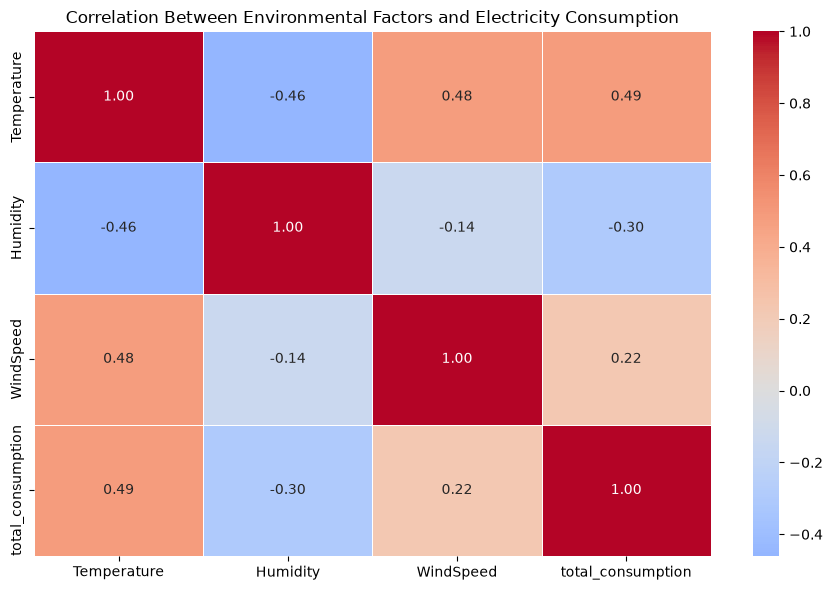

In [43]:
# Correlation heatmap

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    center=0
)

plt.title('Correlation Between Environmental Factors and Electricity Consumption')
plt.tight_layout()
plt.show()


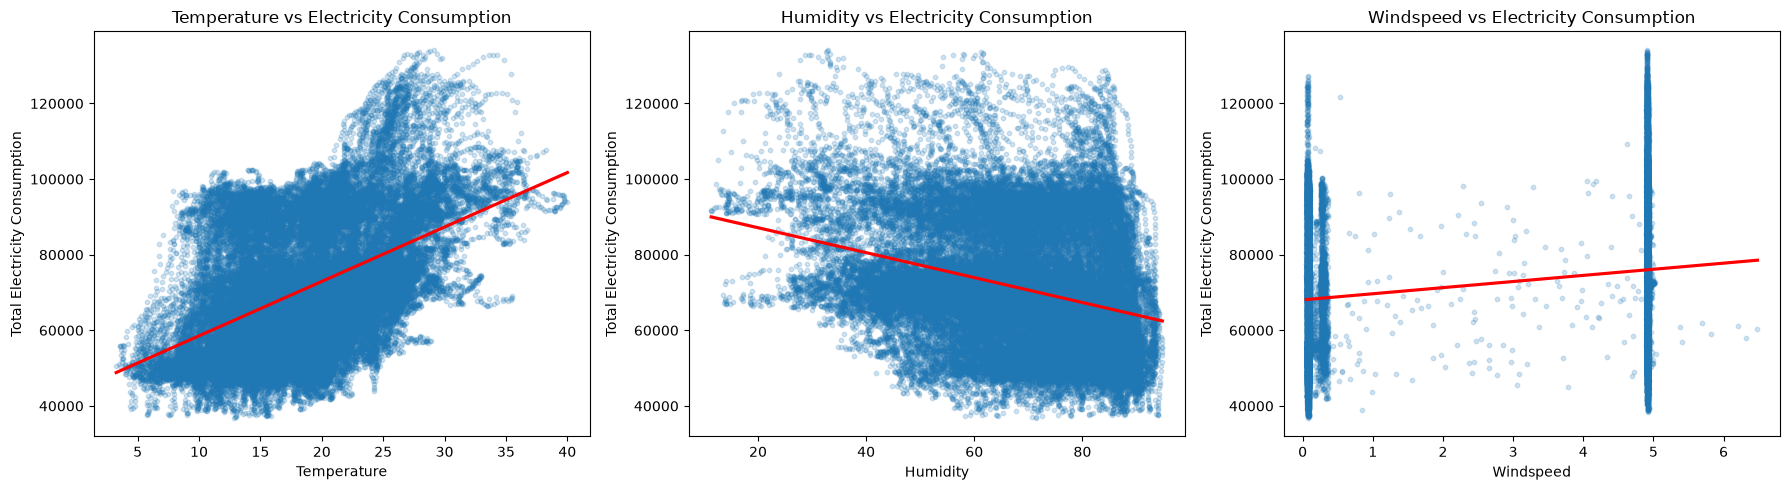

In [44]:
# Scatter plot analysis

environmental_variables = ['Temperature', 'Humidity', 'WindSpeed']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, variable in zip(axes, environmental_variables):
    sns.regplot(
        data=df,
        x=variable,
        y='total_consumption',
        scatter_kws={'alpha': 0.2, 's': 10},
        line_kws={'color': 'red'},
        ax=ax
    )

    ax.set_title(f'{variable.title()} vs Electricity Consumption')
    ax.set_xlabel(variable.title())
    ax.set_ylabel('Total Electricity Consumption')

plt.tight_layout()
plt.show()


In [45]:

# Calculate correlations for each zone

zone_correlations = {}

for zone in zone_columns:
    zone_correlations[zone] = df[
        environmental_variables + [zone]
    ].corr()[zone].drop(zone)

zone_correlation_df = pd.DataFrame(zone_correlations)

print(zone_correlation_df)


             PowerConsumption_Zone1  PowerConsumption_Zone2  \
Temperature                0.440221                0.382428   
Humidity                  -0.287421               -0.294961   
WindSpeed                  0.167444                0.146413   

             PowerConsumption_Zone3  
Temperature                0.489527  
Humidity                  -0.233022  
WindSpeed                  0.278641  


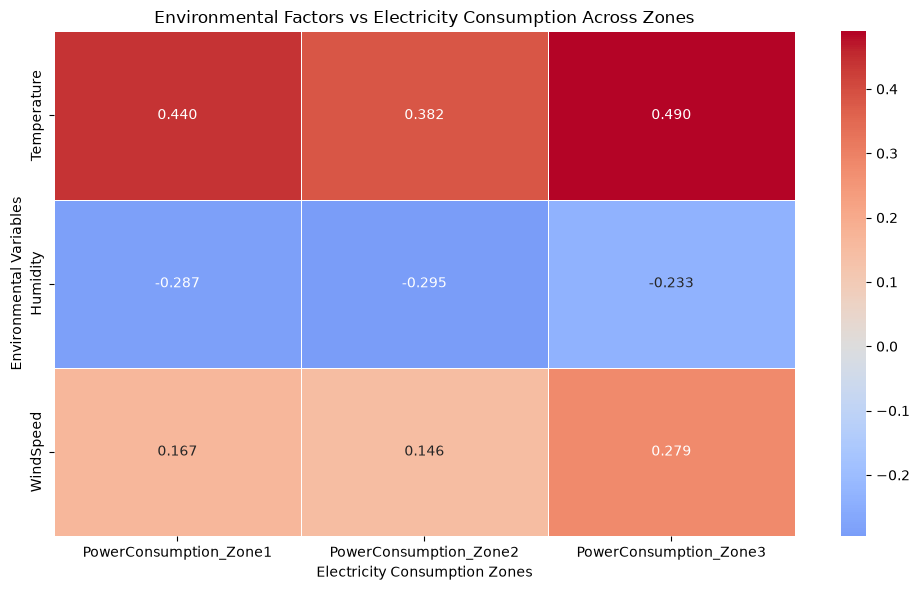

In [46]:

plt.figure(figsize=(10, 6))

sns.heatmap(
    zone_correlation_df,
    annot=True,
    cmap='coolwarm',
    fmt='.3f',
    center=0,
    linewidths=0.5
)

plt.title('Environmental Factors vs Electricity Consumption Across Zones')
plt.xlabel('Electricity Consumption Zones')
plt.ylabel('Environmental Variables')

plt.tight_layout()
plt.show()


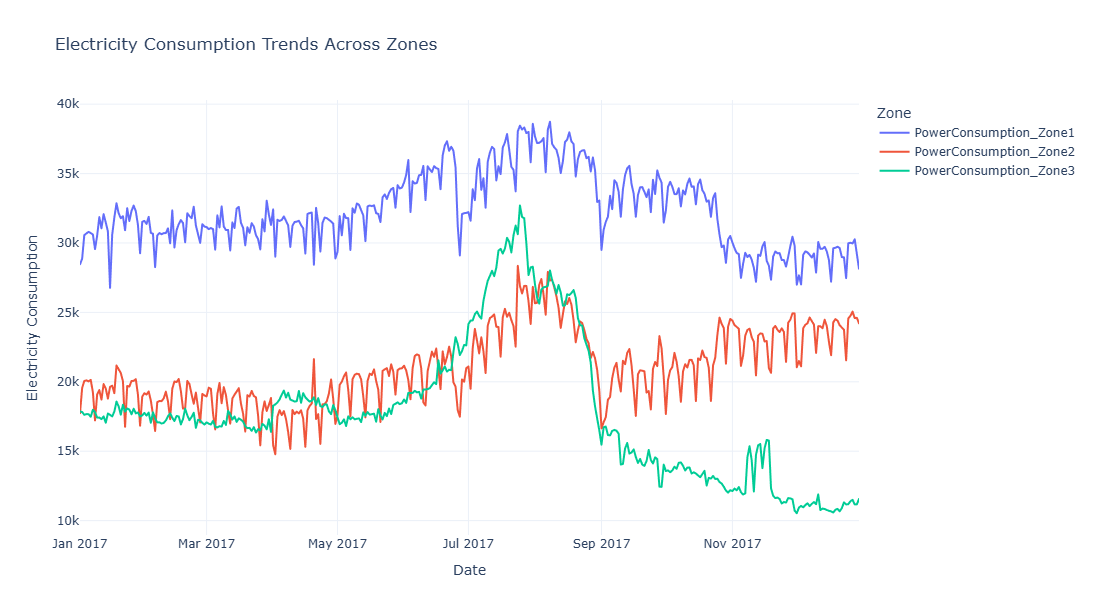

In [53]:
# Task 5
# Data visualization
# Electricity consumption trends over time

import plotly.express as px

daily_trend = df.groupby('Date')[consumption_cols].mean().reset_index()

fig = px.line(
    daily_trend,
    x='Date',
    y=consumption_cols,
    title='Electricity Consumption Trends Across Zones',
    labels={
        'Date': 'Date',
        'value': 'Electricity Consumption',
        'variable': 'Zone'
    }
)

fig.update_traces(
    hovertemplate=
    'Date: %{x}<br>' +
    'Consumption: %{y:,.2f}<extra>%{fullData.name}</extra>'
)

fig.update_layout(
    hovermode='closest',
    template='plotly_white',
    height=600,
    width=1200
)

fig.show()

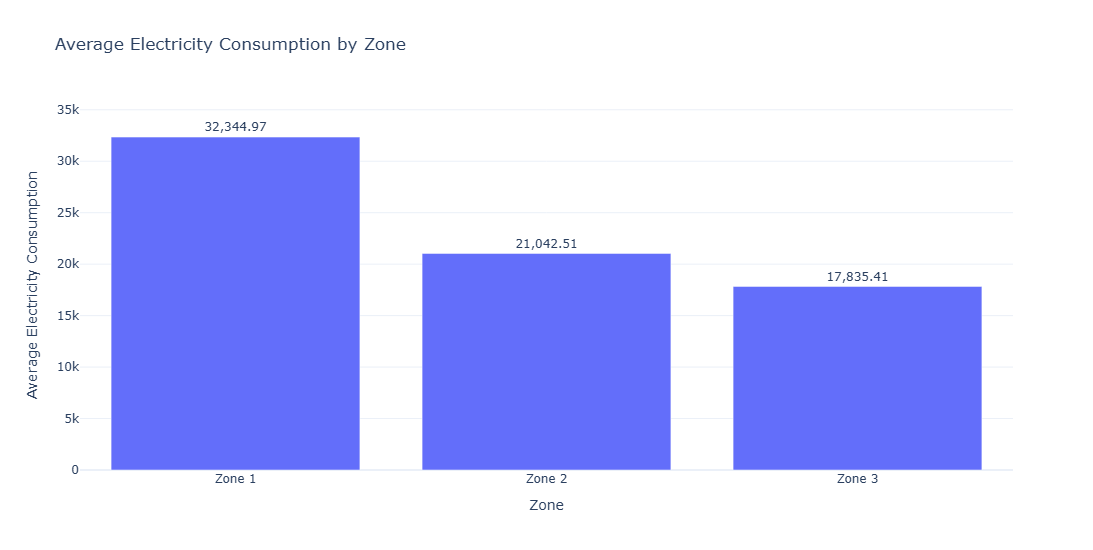

In [55]:
# Average consumption by zone

zone_avg = df[consumption_cols].mean().reset_index()

zone_avg.columns = ['Zone', 'Average Consumption']

zone_avg['Zone'] = zone_avg['Zone'].replace({
    'PowerConsumption_Zone1': 'Zone 1',
    'PowerConsumption_Zone2': 'Zone 2',
    'PowerConsumption_Zone3': 'Zone 3'
})

fig = px.bar(
    zone_avg,
    x='Zone',
    y='Average Consumption',
    title='Average Electricity Consumption by Zone',
    text='Average Consumption',
    hover_data={'Average Consumption': ':.2f'}
)

fig.update_traces(
    texttemplate='%{y:,.2f}',
    textposition='outside'
)

fig.update_layout(
    template='plotly_white',
    height=550,
    yaxis_title='Average Electricity Consumption'
)

fig.show()

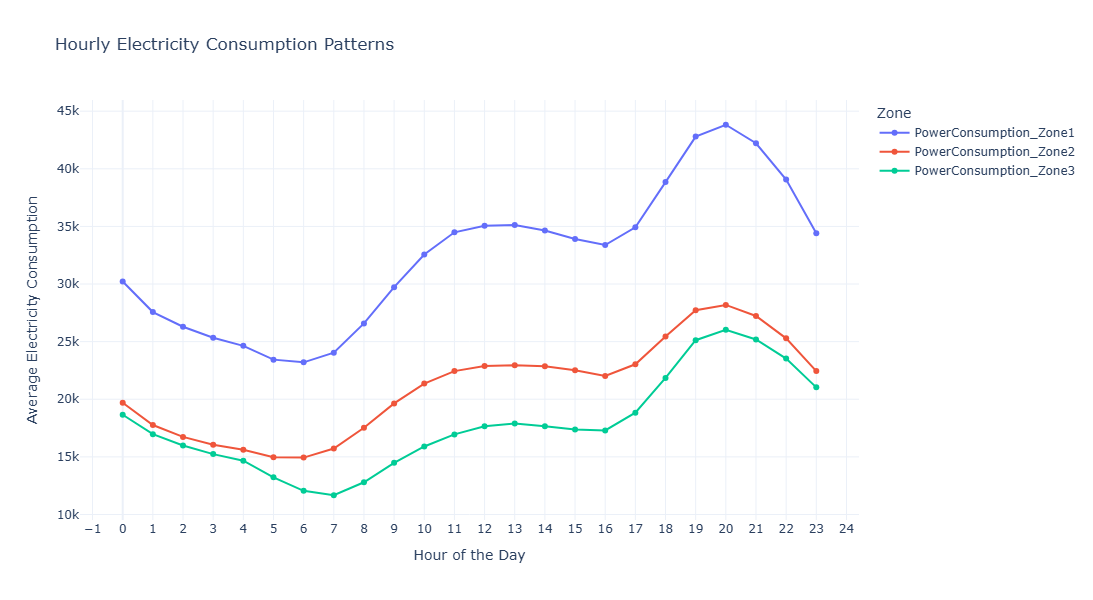

In [56]:
# Hourly consumption patterns

hourly_data = df.groupby('Hour')[consumption_cols].mean().reset_index()

hourly_long = hourly_data.melt(
    id_vars='Hour',
    var_name='Zone',
    value_name='Consumption'
)

fig = px.line(
    hourly_long,
    x='Hour',
    y='Consumption',
    color='Zone',
    markers=True,
    title='Hourly Electricity Consumption Patterns',
    hover_data={'Hour': True, 'Consumption': ':.2f'}
)

fig.update_layout(
    template='plotly_white',
    height=600,
    hovermode='x unified',
    xaxis=dict(
        tickmode='linear',
        dtick=1,
        title='Hour of the Day'
    ),
    yaxis_title='Average Electricity Consumption'
)

fig.show()

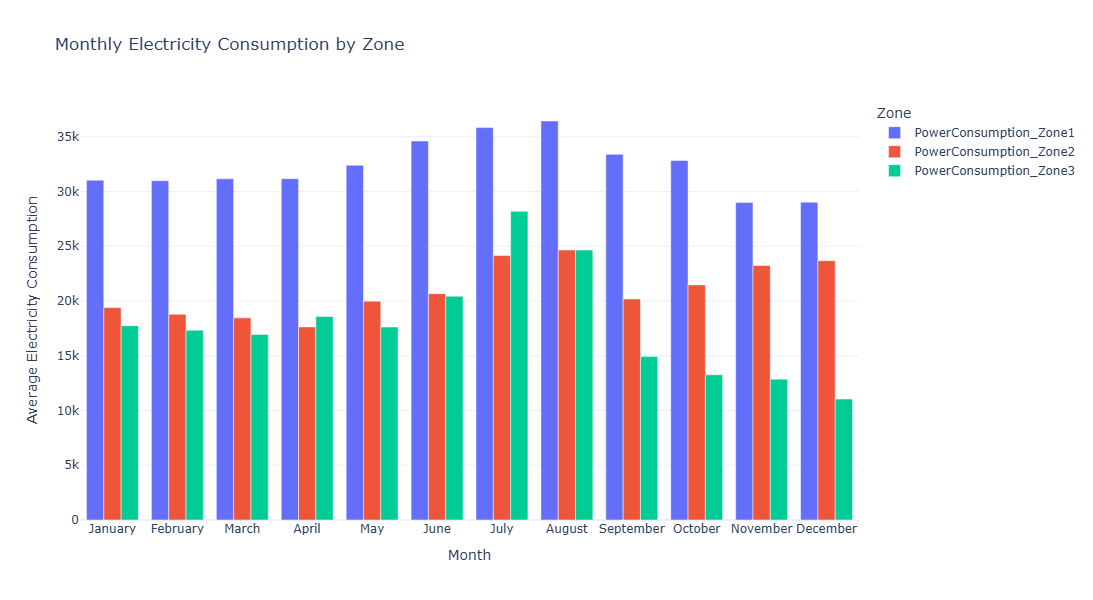

In [57]:
# Monthly consumption patterns

monthly_data = df.groupby('Month')[consumption_cols].mean().reset_index()

monthly_long = monthly_data.melt(
    id_vars='Month',
    var_name='Zone',
    value_name='Consumption'
)

month_names = {
    1: 'January', 2: 'February', 3: 'March',
    4: 'April', 5: 'May', 6: 'June',
    7: 'July', 8: 'August', 9: 'September',
    10: 'October', 11: 'November', 12: 'December'
}

monthly_long['Month'] = monthly_long['Month'].map(month_names)

fig = px.bar(
    monthly_long,
    x='Month',
    y='Consumption',
    color='Zone',
    barmode='group',
    title='Monthly Electricity Consumption by Zone',
    hover_data={'Consumption': ':.2f'}
)

fig.update_layout(
    template='plotly_white',
    height=600,
    xaxis_title='Month',
    yaxis_title='Average Electricity Consumption',
    hovermode='x unified'
)

fig.show()

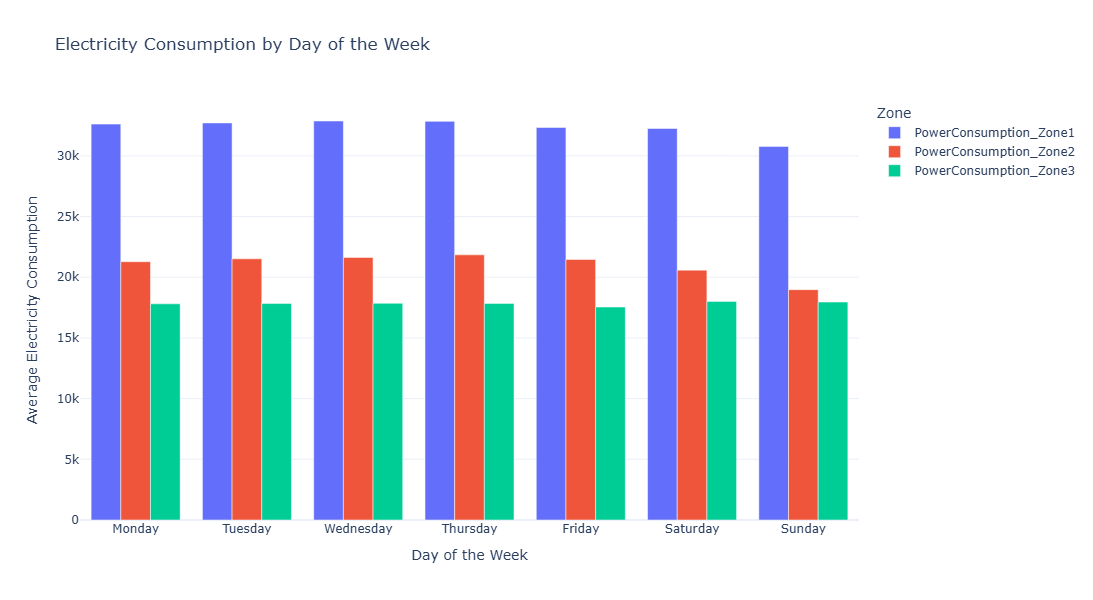

In [59]:
# Day-of-week comparisons

week_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

weekly_data = df.groupby('Day_of_Week')[consumption_cols].mean()

weekly_data = weekly_data.reindex(week_order).reset_index()

weekly_long = weekly_data.melt(
    id_vars='Day_of_Week',
    var_name='Zone',
    value_name='Consumption'
)

fig = px.bar(
    weekly_long,
    x='Day_of_Week',
    y='Consumption',
    color='Zone',
    barmode='group',
    title='Electricity Consumption by Day of the Week',
    hover_data={'Consumption': ':.2f'}
)

fig.update_layout(
    template='plotly_white',
    height=600,
    xaxis_title='Day of the Week',
    yaxis_title='Average Electricity Consumption',
    hovermode='x unified'
)

fig.show()

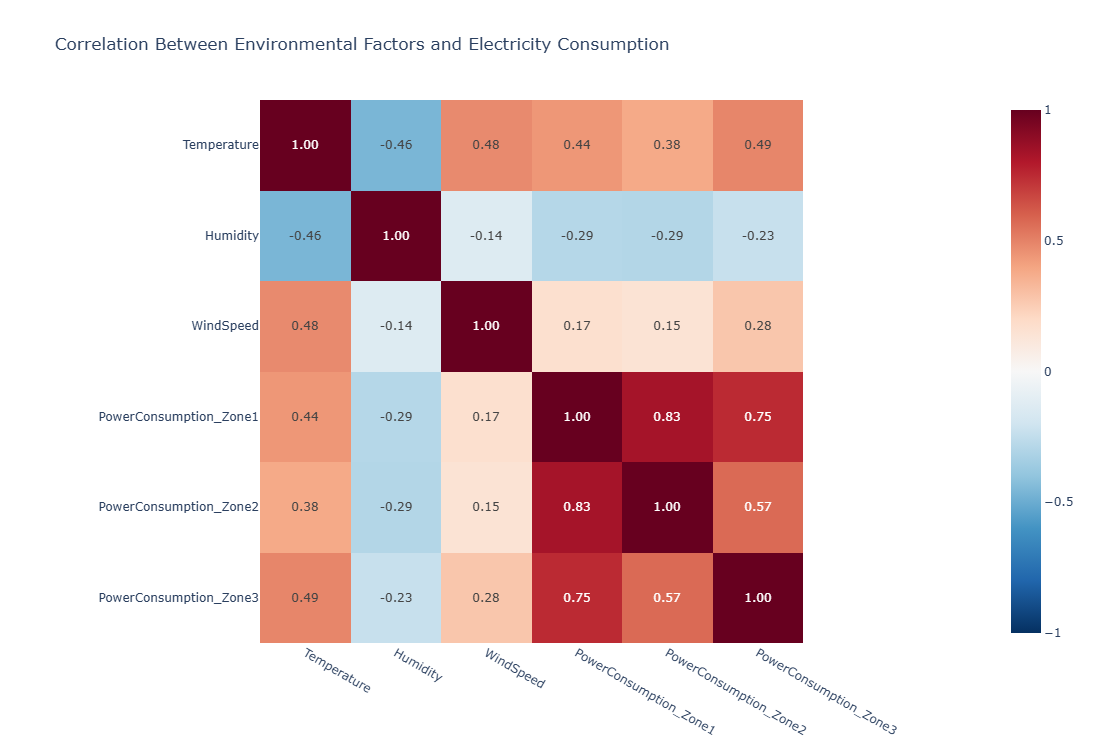

In [62]:
# Environmental factor relationships

correlation_cols = [
    'Temperature',
    'Humidity',
    'WindSpeed',
    'PowerConsumption_Zone1',
    'PowerConsumption_Zone2',
    'PowerConsumption_Zone3'
]

correlation_matrix = df[correlation_cols].corr()

fig = px.imshow(
    correlation_matrix,
    text_auto='.2f',
    color_continuous_scale='RdBu_r',
    zmin=-1,
    zmax=1,
    title='Correlation Between Environmental Factors and Electricity Consumption'
)

fig.update_layout(
    template='plotly_white',
    height=750,
    width=900
)

fig.show()

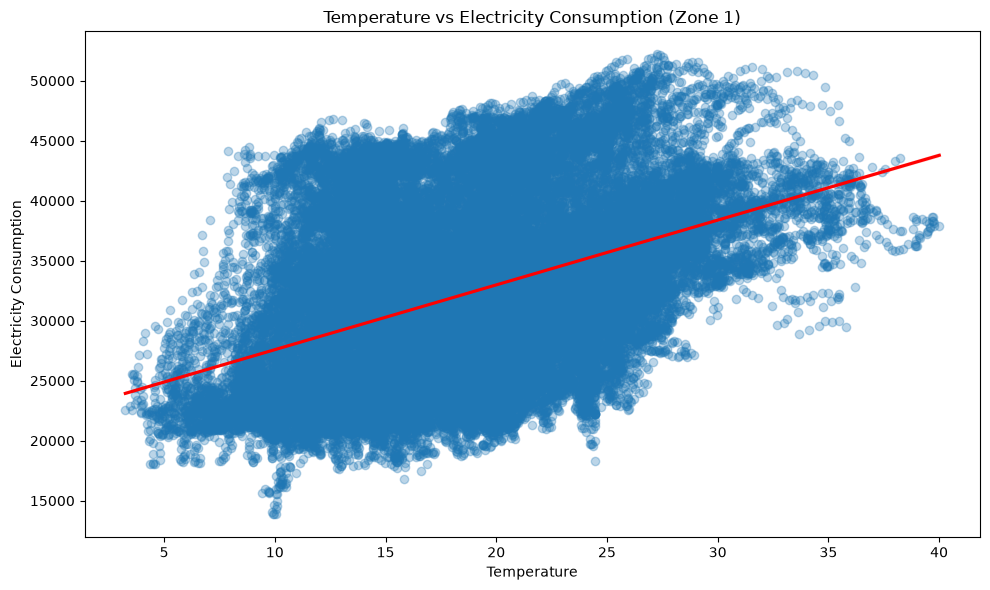

In [65]:
# temperature vs electricity for zone 1
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x='Temperature',
    y='PowerConsumption_Zone1',
    scatter_kws={'alpha': 0.3},
    line_kws={'color': 'red'}
)

plt.title('Temperature vs Electricity Consumption (Zone 1)')
plt.xlabel('Temperature')
plt.ylabel('Electricity Consumption')
plt.tight_layout()
plt.show()

C:\Users\Adediwura\AppData\Local\Temp\ipykernel_19272\1186412535.py:21: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
C:\Users\Adediwura\AppData\Local\Programs\Python\Python314\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


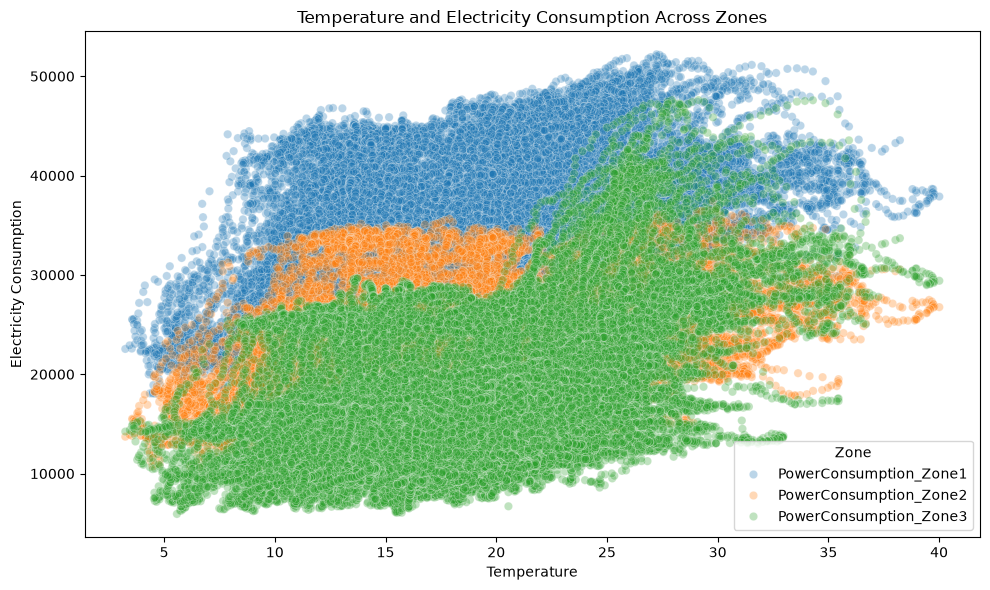

In [64]:
# temperature vs electricity across zones
temperature_data = df.melt(
    id_vars='Temperature',
    value_vars=consumption_cols,
    var_name='Zone',
    value_name='Consumption'
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=temperature_data,
    x='Temperature',
    y='Consumption',
    hue='Zone',
    alpha=0.3
)

plt.title('Temperature and Electricity Consumption Across Zones')
plt.xlabel('Temperature')
plt.ylabel('Electricity Consumption')
plt.tight_layout()
plt.show()

C:\Users\Adediwura\AppData\Local\Temp\ipykernel_19272\400940396.py:21: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
C:\Users\Adediwura\AppData\Local\Programs\Python\Python314\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


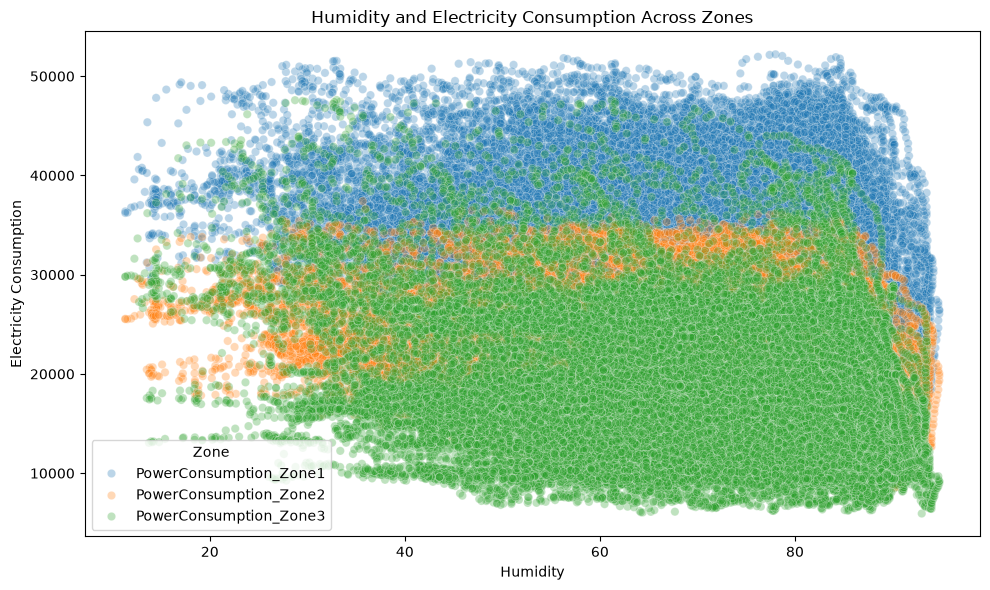

In [66]:
Humidity vs electricity across zones

humidity_data = df.melt(
    id_vars='Humidity',
    value_vars=consumption_cols,
    var_name='Zone',
    value_name='Consumption'
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=humidity_data,
    x='Humidity',
    y='Consumption',
    hue='Zone',
    alpha=0.3
)

plt.title('Humidity and Electricity Consumption Across Zones')
plt.xlabel('Humidity')
plt.ylabel('Electricity Consumption')
plt.tight_layout()
plt.show()

C:\Users\Adediwura\AppData\Local\Temp\ipykernel_19272\1383745148.py:23: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
C:\Users\Adediwura\AppData\Local\Programs\Python\Python314\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


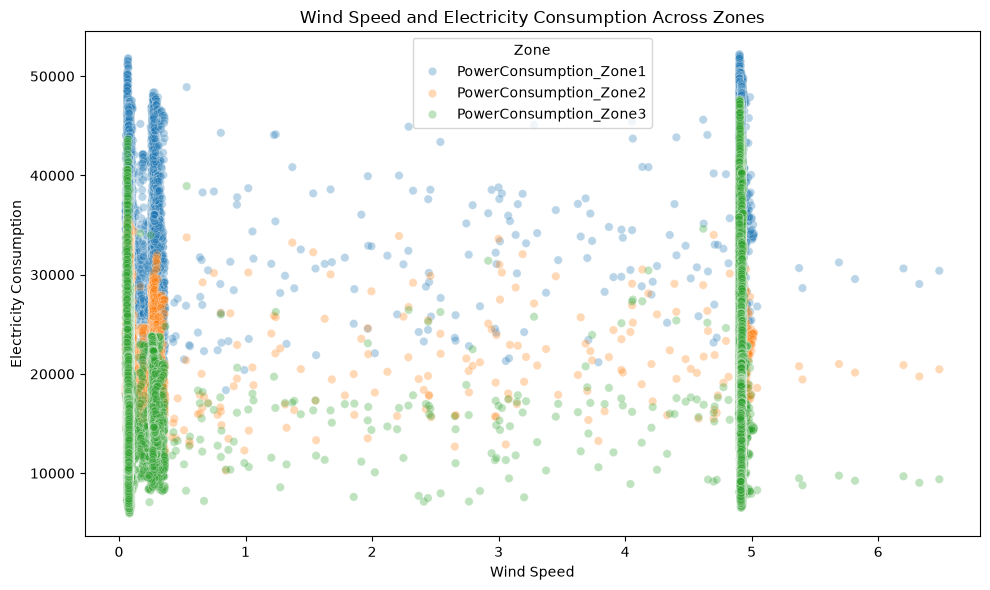

In [67]:
# Windspeed vs electricity across zones

wind_data = df.melt(
    id_vars='WindSpeed',
    value_vars=consumption_cols,
    var_name='Zone',
    value_name='Consumption'
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=wind_data,
    x='WindSpeed',
    y='Consumption',
    hue='Zone',
    alpha=0.3
)

plt.title('Wind Speed and Electricity Consumption Across Zones')
plt.xlabel('Wind Speed')
plt.ylabel('Electricity Consumption')
plt.tight_layout()
plt.show()

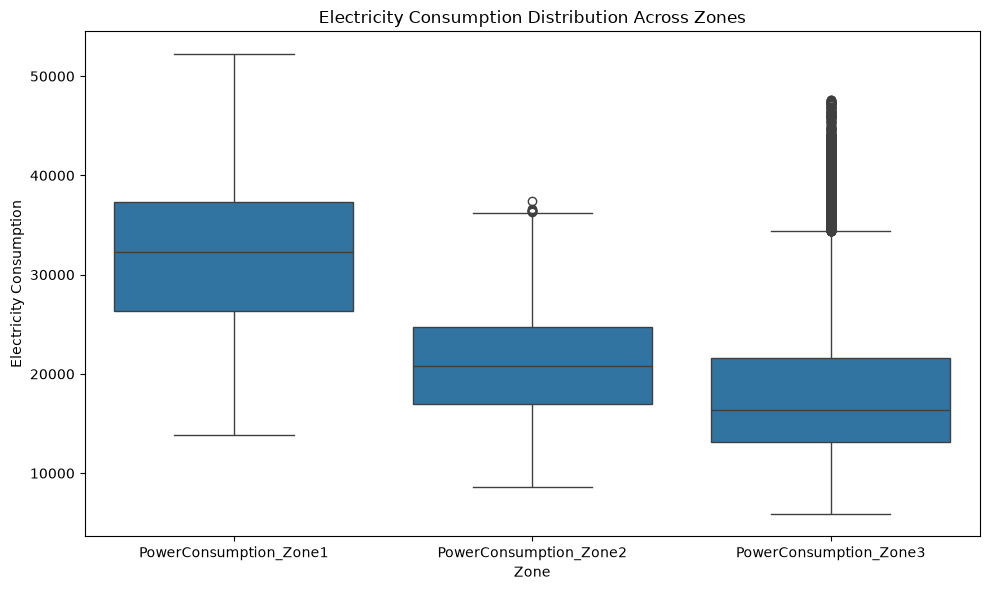

In [68]:
# Comparison of the three zones
# Boxplot comparison

zone_data = df[consumption_cols].melt(
    var_name='Zone',
    value_name='Consumption'
)

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=zone_data,
    x='Zone',
    y='Consumption'
)

plt.title('Electricity Consumption Distribution Across Zones')
plt.xlabel('Zone')
plt.ylabel('Electricity Consumption')
plt.tight_layout()
plt.show()

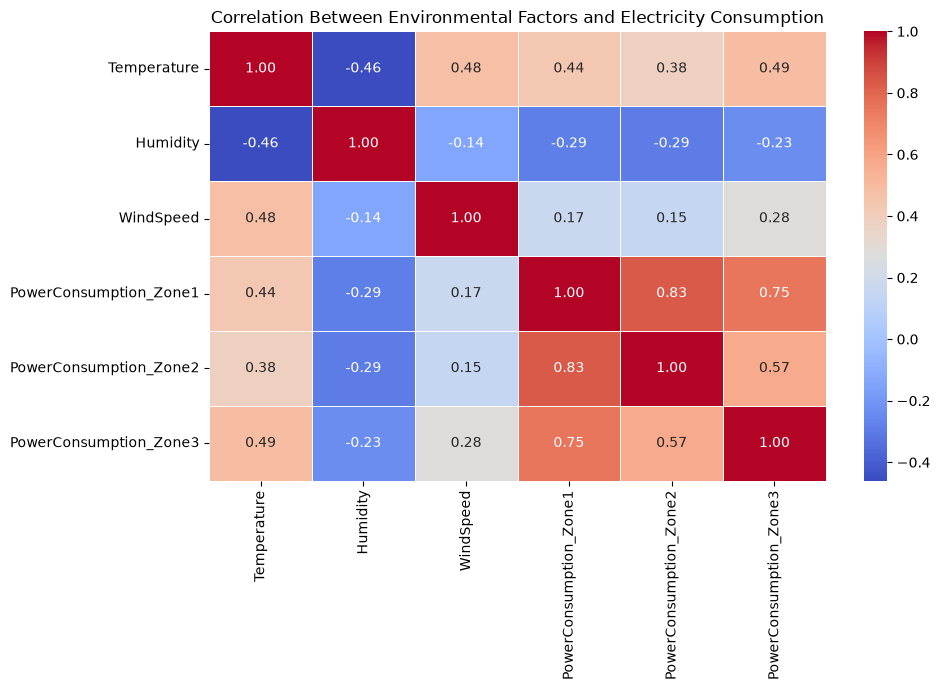

In [69]:
# Correlation heatmap

correlation_cols = [
    'Temperature',
    'Humidity',
    'WindSpeed',
    'PowerConsumption_Zone1',
    'PowerConsumption_Zone2',
    'PowerConsumption_Zone3'
]

correlation_matrix = df[correlation_cols].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Between Environmental Factors and Electricity Consumption')
plt.tight_layout()
plt.show()